In [25]:
files_to_check = [
    PROCESSED_DIR / "X_train_smote.parquet",
    PROCESSED_DIR / "y_train_smote.parquet",
    SYNTHETIC_DIR / "smote_fraud_synthetic.parquet",
    METRICS_DIR / "smote_summary.csv",
    METRICS_DIR / "smote_feature_fidelity.csv",
    FIGURES_DIR / "smote_class_distribution_before_after.png",
    FIGURES_DIR / "smote_pca_real_vs_synthetic.png"
]

for path in files_to_check:
    print(
        path.name,
        "→",
        path.exists()
    )

X_train_smote.parquet → True
y_train_smote.parquet → True
smote_fraud_synthetic.parquet → True
smote_summary.csv → True
smote_feature_fidelity.csv → True
smote_class_distribution_before_after.png → True
smote_pca_real_vs_synthetic.png → True


In [24]:
smote_synthetic_df = (
    X_smote_synthetic.copy()
)

smote_synthetic_df["Class"] = 1

smote_synthetic_df.to_parquet(
    SYNTHETIC_DIR / "smote_fraud_synthetic.parquet",
    index=False
)

In [23]:
X_train_smote.to_parquet(
    PROCESSED_DIR / "X_train_smote.parquet",
    index=False
)

y_train_smote.to_frame(
    name="Class"
).to_parquet(
    PROCESSED_DIR / "y_train_smote.parquet",
    index=False
)

In [22]:
smote_fidelity.to_csv(
    METRICS_DIR / "smote_feature_fidelity.csv",
    index=False
)

smote_summary.to_csv(
    METRICS_DIR / "smote_summary.csv",
    index=False
)

In [21]:
smote_summary = pd.DataFrame({
    "Mesure": [
        "Train original",
        "Fraudes réelles Train",
        "Normales Train",
        "Fraudes après SMOTE",
        "Fraudes synthétiques créées",
        "Taille Train après SMOTE",
        "NaN synthétiques",
        "Inf synthétiques",
        "Doublons synthétiques",
        "Copies exactes de fraudes réelles"
    ],
    "Valeur": [
        len(X_train),
        int(before_counts.loc[1]),
        int(before_counts.loc[0]),
        int(after_counts.loc[1]),
        int(n_synthetic),
        len(X_train_smote),
        int(nan_count),
        int(inf_count),
        int(synthetic_duplicates),
        int(exact_matches)
    ]
})

display(smote_summary)

,Mesure,Valeur
0,Train original,198608
1,Fraudes réelles Train,331
2,Normales Train,198277
3,Fraudes après SMOTE,198277
4,Fraudes synthétiques créées,197946
5,Taille Train après SMOTE,396554
6,NaN synthétiques,0
7,Inf synthétiques,0
8,Doublons synthétiques,0
9,Copies exactes de fraudes réelles,0


In [20]:
display(
    smote_fidelity
    .sort_values(
        "KS_Statistic",
        ascending=False
    )
)

,Feature,KS_Statistic,Wasserstein_Distance
23,V23,0.057478,0.002541
26,V26,0.050116,0.008212
21,V21,0.049997,0.003402
25,V25,0.049388,0.005117
28,V28,0.048740,0.001279
29,Amount,0.048493,0.008042
6,V6,0.048374,0.002871
22,V22,0.048371,0.005312
20,V20,0.047013,0.002220
27,V27,0.046726,0.002642


In [19]:
fidelity_results = []

for column in X_train.columns:

    real_values = X_real_fraud[column].to_numpy()
    synthetic_values = X_smote_synthetic[column].to_numpy()

    ks_stat = ks_2samp(
        real_values,
        synthetic_values
    ).statistic

    wasserstein = wasserstein_distance(
        real_values,
        synthetic_values
    )

    fidelity_results.append({
        "Feature": column,
        "KS_Statistic": ks_stat,
        "Wasserstein_Distance": wasserstein
    })

smote_fidelity = pd.DataFrame(
    fidelity_results
)

## Évaluation statistique préliminaire des données générées

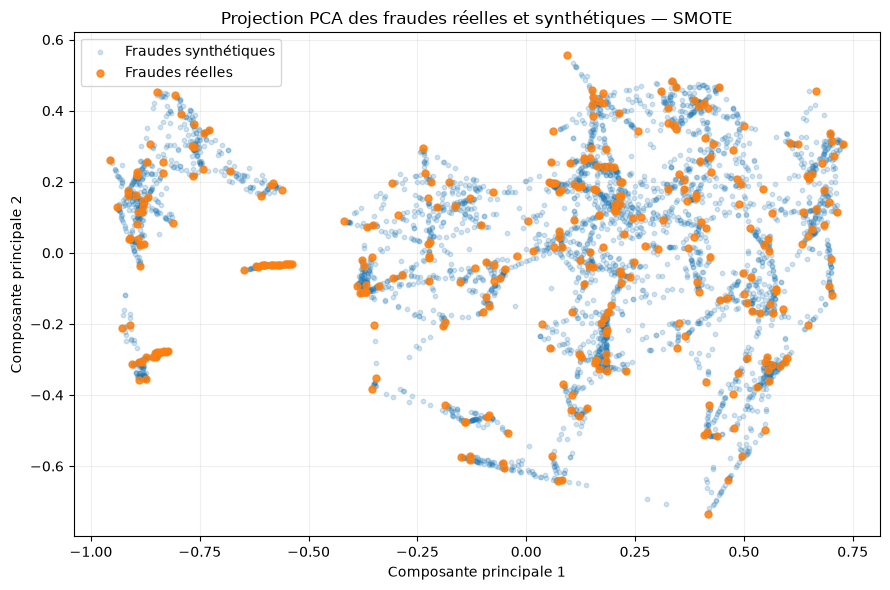

In [18]:
fig, ax = plt.subplots(
    figsize=(9, 6)
)

real_mask = labels_vis == "Fraude réelle"
synthetic_mask = labels_vis == "Fraude synthétique"

ax.scatter(
    X_vis_pca[synthetic_mask, 0],
    X_vis_pca[synthetic_mask, 1],
    s=10,
    alpha=0.20,
    label="Fraudes synthétiques"
)

ax.scatter(
    X_vis_pca[real_mask, 0],
    X_vis_pca[real_mask, 1],
    s=25,
    alpha=0.85,
    label="Fraudes réelles"
)

ax.set_xlabel("Composante principale 1")
ax.set_ylabel("Composante principale 2")

ax.set_title(
    "Projection PCA des fraudes réelles et synthétiques — SMOTE"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "smote_pca_real_vs_synthetic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
N_SYNTHETIC_VIS = min(
    5000,
    len(X_smote_synthetic)
)

X_synthetic_vis = (
    X_smote_synthetic
    .sample(
        n=N_SYNTHETIC_VIS,
        random_state=42
    )
    .reset_index(drop=True)
)

X_vis = pd.concat(
    [
        X_real_fraud,
        X_synthetic_vis
    ],
    ignore_index=True
)

labels_vis = np.array(
    ["Fraude réelle"] * len(X_real_fraud)
    +
    ["Fraude synthétique"] * len(X_synthetic_vis)
)

pca = PCA(
    n_components=2
)

X_vis_pca = pca.fit_transform(
    X_vis
)

print(
    "Variance expliquée par les deux composantes :",
    pca.explained_variance_ratio_.sum()
)

Variance expliquée par les deux composantes : 0.6722255525367047


## Projection des fraudes réelles et synthétiques

In [16]:
real_hashes = set(
    pd.util.hash_pandas_object(
        X_real_fraud,
        index=False
    ).tolist()
)

synthetic_hashes = pd.util.hash_pandas_object(
    X_smote_synthetic,
    index=False
)

exact_matches = synthetic_hashes.isin(
    real_hashes
).sum()

print(
    "Transactions synthétiques exactement identiques à une fraude réelle :",
    exact_matches
)

Transactions synthétiques exactement identiques à une fraude réelle : 0


In [15]:
real_min = X_real_fraud.min()
real_max = X_real_fraud.max()

outside_bounds = (
    (X_smote_synthetic < real_min)
    |
    (X_smote_synthetic > real_max)
)

n_outside = int(
    outside_bounds.sum().sum()
)

print(
    "Valeurs synthétiques hors min/max des fraudes réelles :",
    n_outside
)

Valeurs synthétiques hors min/max des fraudes réelles : 0


In [14]:
X_real_fraud = (
    X_train.loc[y_train == 1]
    .reset_index(drop=True)
)

print(
    "Fraudes réelles Train :",
    X_real_fraud.shape
)

Fraudes réelles Train : (331, 30)


In [13]:
synthetic_duplicates = (
    X_smote_synthetic
    .duplicated()
    .sum()
)

print(
    "Doublons exacts parmi les données synthétiques :",
    synthetic_duplicates
)

Doublons exacts parmi les données synthétiques : 0


In [12]:
nan_count = X_smote_synthetic.isna().sum().sum()

inf_count = np.isinf(
    X_smote_synthetic.to_numpy()
).sum()

print("NaN :", nan_count)
print("Infini :", inf_count)

NaN : 0
Infini : 0


## Contrôle d'intégrité des données synthétiques

In [11]:
display(
    X_smote_synthetic.head(10)
)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.770301,0.978410,0.799706,0.639152,0.497583,0.504251,0.511389,0.546729,0.792446,0.359528,...,0.387204,0.563285,0.429377,0.591824,0.412884,0.558109,0.435858,0.663744,0.264168,0.000000
1,0.492488,0.939244,0.786691,0.758964,0.382137,0.481164,0.535000,0.545590,0.795273,0.422320,...,0.383007,0.563720,0.461700,0.592926,0.356347,0.544186,0.407974,0.651734,0.256117,0.070388
2,0.814493,0.956145,0.767772,0.754280,0.250394,0.500048,0.530605,0.561931,0.784237,0.471719,...,0.375520,0.569564,0.507156,0.595905,0.512634,0.491208,0.432591,0.656335,0.257509,0.116351
3,0.888681,0.981254,0.758809,0.732944,0.284940,0.477679,0.526568,0.565481,0.785296,0.498086,...,0.391917,0.563430,0.468461,0.589375,0.374450,0.531321,0.327452,0.650046,0.258557,0.588210
4,0.671873,0.932398,0.778358,0.726696,0.297924,0.463758,0.526249,0.525334,0.790492,0.430917,...,0.388072,0.574178,0.526287,0.595118,0.367518,0.530893,0.434696,0.651439,0.255151,0.291585
5,0.726880,0.942750,0.783839,0.715934,0.246560,0.473587,0.523204,0.539968,0.792530,0.383867,...,0.380262,0.561769,0.441584,0.590194,0.467300,0.539232,0.523117,0.652712,0.261058,0.358999
6,0.047919,0.937208,0.818885,0.626327,0.528442,0.489760,0.488802,0.533300,0.799935,0.347930,...,0.389325,0.569317,0.451066,0.584280,0.375275,0.611643,0.499865,0.663251,0.264755,0.070388
7,0.535304,0.853222,0.811205,0.564922,0.543706,0.423236,0.498920,0.468995,0.828180,0.314210,...,0.388688,0.579842,0.464198,0.595634,0.349250,0.544588,0.552658,0.668079,0.245516,0.000000
8,0.543244,0.761550,0.844945,0.343418,0.601510,0.318693,0.449565,0.386949,0.869220,0.307048,...,0.365774,0.606999,0.507958,0.575370,0.478301,0.547062,0.473307,0.596952,0.244136,0.506745
9,0.934138,0.903288,0.808339,0.621511,0.325075,0.464021,0.475936,0.512996,0.809290,0.359291,...,0.382906,0.577962,0.487652,0.584570,0.366300,0.527930,0.447251,0.660201,0.263294,0.033484


In [10]:
n_original = len(X_train)

X_smote_synthetic = (
    X_train_smote
    .iloc[n_original:]
    .reset_index(drop=True)
)

y_smote_synthetic = (
    y_train_smote
    .iloc[n_original:]
    .reset_index(drop=True)
)

print("Données synthétiques :", X_smote_synthetic.shape)

print(
    "Classes présentes :",
    y_smote_synthetic.unique()
)

Données synthétiques : (197946, 30)
Classes présentes : [1]


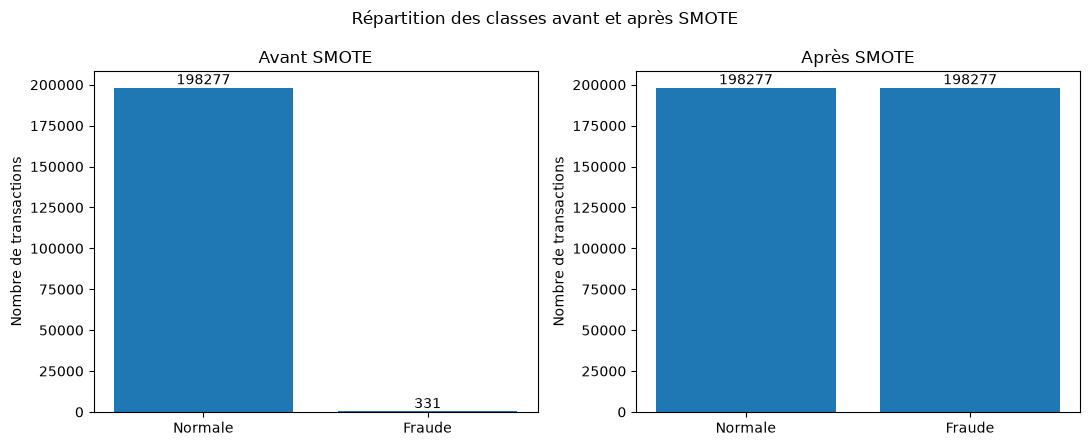

In [9]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4.5)
)

labels = ["Normale", "Fraude"]

axes[0].bar(
    labels,
    [before_counts.loc[0], before_counts.loc[1]]
)

axes[0].set_title("Avant SMOTE")
axes[0].set_ylabel("Nombre de transactions")

axes[1].bar(
    labels,
    [after_counts.loc[0], after_counts.loc[1]]
)

axes[1].set_title("Après SMOTE")
axes[1].set_ylabel("Nombre de transactions")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%d")

fig.suptitle(
    "Répartition des classes avant et après SMOTE"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "smote_class_distribution_before_after.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Comparaison de la répartition des classes avant et après SMOTE

In [8]:
after_counts = y_train_smote.value_counts().sort_index()

print("Avant SMOTE :")
print(before_counts)

print("\nAprès SMOTE :")
print(after_counts)

n_synthetic = len(X_train_smote) - len(X_train)

print("\nNombre d'observations synthétiques créées :", n_synthetic)

Avant SMOTE :
Class
0    198277
1       331
Name: count, dtype: int64

Après SMOTE :
Class
0    198277
1    198277
Name: count, dtype: int64

Nombre d'observations synthétiques créées : 197946


In [7]:
X_train_smote = pd.DataFrame(
    X_train_smote,
    columns=X_train.columns
)

y_train_smote = pd.Series(
    y_train_smote,
    name="Class"
)

print("SMOTE terminé.")

SMOTE terminé.


In [6]:
smote = SMOTE(
    sampling_strategy=1.0,
    k_neighbors=5,
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

## Application de SMOTE sur l'ensemble d'entraînement

## Principe de SMOTE

SMOTE génère de nouvelles observations de la classe minoritaire en interpolant entre des observations frauduleuses réelles proches.

Pour une observation frauduleuse `x_i` et l'un de ses voisins frauduleux `x_j`, une nouvelle observation peut être générée selon :

x_new = x_i + λ × (x_j - x_i)

où λ est une valeur aléatoire comprise entre 0 et 1.

SMOTE ne copie donc pas simplement une transaction existante : il crée un nouveau point situé entre deux transactions frauduleuses voisines.

In [5]:
before_counts = y_train.value_counts().sort_index()

print("Répartition avant SMOTE :")
print(before_counts)

print()
print("Transactions normales :", before_counts.loc[0])
print("Transactions frauduleuses :", before_counts.loc[1])
print(
    "Taux de fraude :",
    round(before_counts.loc[1] / len(y_train) * 100, 4),
    "%"
)

Répartition avant SMOTE :
Class
0    198277
1       331
Name: count, dtype: int64

Transactions normales : 198277
Transactions frauduleuses : 331
Taux de fraude : 0.1667 %


In [4]:
X_train = pd.read_parquet(
    PROCESSED_DIR / "X_train.parquet"
)

y_train = pd.read_parquet(
    PROCESSED_DIR / "y_train.parquet"
)["Class"]

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

X_train : (198608, 30)
y_train : (198608,)


## Chargement de l'ensemble d'entraînement

In [3]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
SYNTHETIC_DIR = PROJECT_ROOT / "results" / "synthetic"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)
SYNTHETIC_DIR.mkdir(parents=True, exist_ok=True)

print("Projet :", PROJECT_ROOT)

Projet : c:\Users\MSI\Desktop\fraud_detection_memoire


In [2]:
print("Imports terminés.")

Imports terminés.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

from scipy.stats import ks_2samp, wasserstein_distance

# 04 — Augmentation des données par SMOTE

Ce notebook applique la méthode SMOTE exclusivement à l'ensemble d'entraînement afin de générer de nouvelles transactions frauduleuses synthétiques.

Les ensembles de validation et de test restent inchangés et composés uniquement de transactions réelles.

Les objectifs sont :
- analyser le déséquilibre initial ;
- appliquer SMOTE sur les données d'entraînement ;
- isoler les transactions synthétiques générées ;
- contrôler leur intégrité ;
- visualiser les données avant et après augmentation ;
- sauvegarder les données générées pour les expérimentations suivantes.